<ol data-start="633" data-end="961">
<li data-start="633" data-end="679">
<p data-start="636" data-end="679"><strong data-start="636" data-end="645">Start</strong> → All data points = one cluster</p>
</li>
<li data-start="680" data-end="799">
<p data-start="683" data-end="799"><strong data-start="683" data-end="692">Split</strong> → သက်ဆိုင်တဲ့ criterion (e.g. minimizing variance, maximizing distance) အတိုင်း cluster ကို 2 groups ခွဲ</p>
</li>
<li data-start="800" data-end="870">
<p data-start="803" data-end="870"><strong data-start="803" data-end="813">Repeat</strong> → ခွဲထားတဲ့ cluster တစ်ခုချင်းစီကို ထပ်ခွဲ (recursive)</p>
</li>
<li data-start="871" data-end="961">
<p data-start="874" data-end="961"><strong data-start="874" data-end="882">Stop</strong> → Desired number of clusters ရှိသွားတဲ့အထိ / splitting criterion မပြည့်မီအထိ</p>
</li>
</ol>

![alt text](image.png)

In [1]:
import matplotlib.pyplot as plt

fruit_tree = {
    "All Fruits": {
        "Citrus": ["Orange", "Lemon"],
        "Non-Citrus": {
            "Berries": ["Strawberry", "Blueberry"],
            "Others": ["Apple", "Banana"]
        }
    }
}

In [2]:
# Step 3: Compute Positions of Nodes Recursively
def compute_positions(tree, x=0, y=0, dx=2):
    positions = {}
    if isinstance(tree, dict):
        all_child_positions = {}
        total_width = 0
        child_centers = []
        for key, subtree in tree.items():
            sub_pos, sub_width = compute_positions(subtree, x + total_width * dx, y - 2, dx)
            all_child_positions.update(sub_pos)
            child_center_x = sum(pos[0] for pos in sub_pos.values()) / len(sub_pos)
            child_centers.append((key, child_center_x))
            total_width += sub_width
        center_x = sum(center for _, center in child_centers) / len(child_centers)
        positions = {key: (center, y) for key, center in child_centers}
        positions.update(all_child_positions)
        return positions, total_width
    elif isinstance(tree, list):
        for i, item in enumerate(tree):
            positions[item] = (x + i * dx, y)
        return positions, len(tree)
    return {}, 0

In [3]:
# Step 4: Extract Parent-Child Edges
def extract_edges(tree, parent=None):
    edges = []
    if isinstance(tree, dict):
        for key, subtree in tree.items():
            if parent:
                edges.append((parent, key))
            edges.extend(extract_edges(subtree, key))
    elif isinstance(tree, list):
        for item in tree:
            if parent:
                edges.append((parent, item))
    return edges

In [4]:
# Step 5: Plot the Tree with Boxes and Arrows
def plot_tree(tree):
    positions, _ = compute_positions(tree)
    edges = extract_edges(tree)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.axis('off')

    for parent, child in edges:
        if parent in positions and child in positions:
            x1, y1 = positions[parent]
            x2, y2 = positions[child]
            ax.plot([x1, x2], [y1, y2], 'k-')

    for node, (x, y) in positions.items():
        if node == "All Fruits":
            color = "lightblue"
        elif node in ["Citrus", "Non-Citrus", "Berries", "Others"]:
            color = "lightgreen"
        else:
            color = "lightyellow"
        ax.text(x, y, node, ha='center', va='center',
                bbox=dict(boxstyle="round", facecolor=color, edgecolor="black"))

    plt.title("Divisive Clustering Tree: Fruit Classification", fontsize=14)
    plt.tight_layout()
    plt.show()

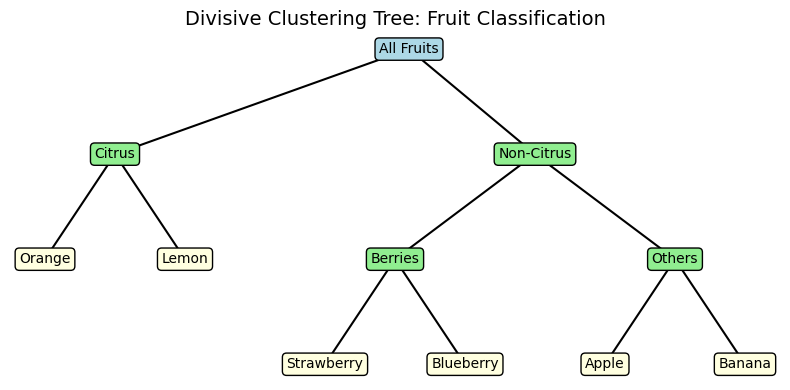

In [5]:
# Step 6: Generate the Tree
plot_tree(fruit_tree)

Real-World Applications of Divisive Clustering

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# -------------------------------
# 1. Sample E-commerce Products
# -------------------------------
products = [
    "iPhone 14 Pro smartphone",
    "Samsung Galaxy S23 phone",
    "MacBook Air M2 laptop",
    "Dell XPS 15 laptop computer",
    "Sony WH-1000XM5 headphones",
    "Bose QuietComfort 45 headphones",
    "Nike Air Zoom Pegasus running shoes",
    "Adidas Ultraboost sneakers",
    "Levi's Slim Fit Jeans",
    "Wrangler Denim Jacket"
]

# -------------------------------
# 2. Convert text to TF-IDF vectors
# -------------------------------
vectorizer = TfidfVectorizer(stop_words="english")
X = vectorizer.fit_transform(products)

# -------------------------------
# 3. Recursive Divisive Clustering Function
# -------------------------------
def divisive_clustering(data, labels, depth=0, max_depth=2):
    """
    data: TF-IDF vectors
    labels: product labels
    depth: current recursion depth
    max_depth: how many levels of hierarchy
    """
    if depth >= max_depth or len(labels) <= 2:
        print("  " * depth + f"Final Cluster ({len(labels)} items): {labels}")
        return
    
    # Apply KMeans with 2 clusters (binary split)
    kmeans = KMeans(n_clusters=2, random_state=42)
    clusters = kmeans.fit_predict(data)
    
    # Split products into 2 groups
    group1 = [labels[i] for i in range(len(labels)) if clusters[i] == 0]
    group2 = [labels[i] for i in range(len(labels)) if clusters[i] == 1]
    
    print("  " * depth + f"Level {depth} Split:")
    
    # Recursive calls for each subgroup
    divisive_clustering(data[clusters == 0], group1, depth+1, max_depth)
    divisive_clustering(data[clusters == 1], group2, depth+1, max_depth)

# -------------------------------
# 4. Run Divisive Clustering
# -------------------------------
divisive_clustering(X, products, max_depth=3)

# 5. Visualization function 


Level 0 Split:
  Level 1 Split:
    Level 2 Split:
      Final Cluster (7 items): ['iPhone 14 Pro smartphone', 'Samsung Galaxy S23 phone', 'MacBook Air M2 laptop', 'Dell XPS 15 laptop computer', 'Sony WH-1000XM5 headphones', 'Bose QuietComfort 45 headphones', 'Nike Air Zoom Pegasus running shoes']
      Final Cluster (1 items): ['Adidas Ultraboost sneakers']
    Final Cluster (1 items): ["Levi's Slim Fit Jeans"]
  Final Cluster (1 items): ['Wrangler Denim Jacket']
